# Unit Responses to Playback Stimuli

In [7]:
# import cPickle as pickle
try:
    import cPickle as pickle
except ImportError:
    import pickle

import matplotlib.pyplot as plt
import numpy as np
import os

from segment_analysis import MultiSegment
from playbacks_analysis import PlaybacksManager
from figure_scripts.unit_summary import get_square_dims, plot_waveforms
import block_io
%load_ext autoreload
%autoreload 2
import config

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
from ipywidgets import interact, widgets
from IPython.display import clear_output
%matplotlib notebook

In [3]:
# block = block_io.load_block("../data/birds/RedGre7705M/sites/RedGre7705M__171214_102641/sorted-resegmented.pkl")
block = block_io.load_block("../data/birds/GreYel3594M/sites/GreYel3594M___170919_094646/sorted-resegmented.pkl")

In [5]:
playbacks_manager = PlaybacksManager(block.segments)
playback_multisegs = playbacks_manager.group_playback_responses()
multisegs = dict((stim_id, playback_multisegs[stim_id]) for stim_id in playbacks_manager.stim_ids)

In [6]:
stim_dropdown = widgets.Dropdown(
    options=[
        ("{vocalizer}, {vocalization_type}: {stim}".format(stim=stim, **multisegs[stim].annotations), playback_multisegs[stim])
            for stim in playbacks_manager.stim_ids],
    value=playback_multisegs[playbacks_manager.stim_ids[0]],
    description="Stim",
    disabled=False
)

electrode_dropdown = widgets.Dropdown(
    options=[(c.name, c) for c in block.channel_indexes],
    value=block.channel_indexes[0],
    description='Electrode:',
    disabled=False,
)

unit_dropdown = widgets.Dropdown(
    options=[("--", None)] + [(e.name, e) for e in electrode_dropdown.value.units],
    value=None if not electrode_dropdown.value.units else electrode_dropdown.value.units[0],
    description='Unit:',
    disabled=False,
)

o = widgets.Output()
o2 = widgets.Output()

def get_dims(n):
    cols = 2
    rows = int(np.ceil(n / float(cols)))
    return cols, rows

def select_electrode(elec):
    elec = elec["owner"]
    elec = elec.options[elec.index][1]
    with o:
        clear_output()
    unit_dropdown.options = [("--", None)] + [(e.name, e) for e in elec.units]

all_units = [unit for elec in block.channel_indexes for unit in elec.units]
def get_unit_idx(unit):
    for unit_idx, u in enumerate(all_units):
        if unit == u:
            break
    return unit_idx

def select_unit(eh):
    u = unit_dropdown.value
    if u is None:
        return
    
    with o:
        clear_output()
#         w, h = get_dims(len(stims))

        multiseg = stim_dropdown.value
        
        fig, ax = plt.subplots(1, 1, figsize=(multiseg.t_stop * 3, 4))
        
        multiseg.plotter.plot_spectrogram(multiseg.segments[0], signal="playback", channel=None, ax=ax)

        ax.set_ylabel("")
        ax.set_xlabel("")
        ax.set_ylim(-ax.get_ylim()[1], ax.get_ylim()[1])
        ax.set_xticks([])
        ax.set_yticks([])
        
        raster_ax = ax.twinx()
        print(u)
        unit_idx = get_unit_idx(u)
        print(u)
        
        multiseg.plotter.plot_raster(unit_idx, ax=raster_ax, mark_noise_epochs=True, elec_idx=electrode_dropdown.value.index)
        raster_ax.set_xlim(0, multiseg.t_stop)
        raster_ax.set_xticks([])
        raster_ax.set_yticks([])
        raster_ax.set_ylim(len(multiseg.segments), -len(multiseg.segments))
        
#         psth_ax = ax.twinx()
#         multiseg.plotter.plot_psth(unit_idx, ax=psth_ax, alpha=0.0, mode="gaussian", convolve_params=(10,))

        plt.show()
        
    with o2:
        clear_output()
        fig, ax = plt.subplots(1, 1, figsize=(4, 2))
        ax.plot(multiseg.waveforms(unit=unit_idx)[0].T, color="Blue", alpha=0.1)
        plt.show()

stim_dropdown.observe(select_unit, "value", "change")
    
electrode_dropdown.observe(select_electrode, "value", "change")
unit_dropdown.observe(select_unit, "value", "change")
    
display(widgets.VBox([
    widgets.HBox([electrode_dropdown, unit_dropdown, stim_dropdown]),
    widgets.VBox([o]),
    widgets.VBox([o2])
]))



VBox(children=(HBox(children=(Dropdown(description='Electrode:', options=(('ADC', <neo.core.channelindex.ChannelIndex object at 0x7fc4891d0240>), ('EventData', <neo.core.channelindex.ChannelIndex object at 0x7fc4891d0400>), ('Amp Elec 0', <neo.core.channelindex.ChannelIndex object at 0x7fc4891d0550>), ('Amp Elec 1', <neo.core.channelindex.ChannelIndex object at 0x7fc4891d0898>), ('Amp Elec 2', <neo.core.channelindex.ChannelIndex object at 0x7fc4891d0b00>), ('Amp Elec 3', <neo.core.channelindex.ChannelIndex object at 0x7fc4891d0d68>), ('Amp Elec 4', <neo.core.channelindex.ChannelIndex object at 0x7fc4891d8048>), ('Amp Elec 5', <neo.core.channelindex.ChannelIndex object at 0x7fc4891d8278>), ('Amp Elec 6', <neo.core.channelindex.ChannelIndex object at 0x7fc4891d84a8>), ('Amp Elec 7', <neo.core.channelindex.ChannelIndex object at 0x7fc4891d8710>), ('Amp Elec 8', <neo.core.channelindex.ChannelIndex object at 0x7fc4891d8940>), ('Amp Elec 9', <neo.core.channelindex.ChannelIndex object at 0x7fc4891d8b38>), ('Amp Elec 10', <neo.core.channelindex.ChannelIndex object at 0x7fc4891d8dd8>), ('Amp Elec 11', <neo.core.channelindex.ChannelIndex object at 0x7fc4891d90b8>), ('Amp Elec 12', <neo.core.channelindex.ChannelIndex object at 0x7fc4891d92e8>), ('Amp Elec 13', <neo.core.channelindex.ChannelIndex object at 0x7fc4891d9588>), ('Amp Elec 14', <neo.core.channelindex.ChannelIndex object at 0x7fc4891d97b8>), ('Amp Elec 15', <neo.core.channelindex.ChannelIndex object at 0x7fc4891d99b0>)), value=<neo.core.channelindex.ChannelIndex object at 0x7fc4891d0240>), Dropdown(description='Unit:', options=(('--', None),), value=None), Dropdown(description='Stim', options=(('con_female, DC: GreHpi3607M_FAF_DC_0.wav', MultiSegment with 46 Segments, 28 Units, t_start=-0.0s, t_stop=1.297966666668799s
{'vocalizer': 'con_female', 'sound_type': 'playback', 'vocalization_type': 'DC'}), ('con_female, DC: GreHpi3607M_FAF_DC_1.wav', MultiSegment with 46 Segments, 28 Units, t_start=-0.0s, t_stop=1.3800333333383605s
{'vocalizer': 'con_female', 'sound_type': 'playback', 'vocalization_type': 'DC'}), ('con_female, DC: GreHpi3607M_FAF_DC_2.wav', MultiSegment with 46 Segments, 28 Units, t_start=-0.0s, t_stop=2.804633333336824s
{'vocalizer': 'con_female', 'sound_type': 'playback', 'vocalization_type': 'DC'}), ('con_female, Te: GreHpi3607M_FAF_Te_0.wav', MultiSegment with 47 Segments, 28 Units, t_start=-0.0s, t_stop=1.339300000003277s
{'vocalizer': 'con_female', 'sound_type': 'playback', 'vocalization_type': 'Te'}), ('con_female, Te: GreHpi3607M_FAF_Te_1.wav', MultiSegment with 46 Segments, 28 Units, t_start=-0.0s, t_stop=1.1284666666688281s
{'vocalizer': 'con_female', 'sound_type': 'playback', 'vocalization_type': 'Te'}), ('con_female, Te: GreHpi3607M_FAF_Te_2.wav', MultiSegment with 46 Segments, 28 Units, t_start=-0.0s, t_stop=1.7167666666719015s
{'vocalizer': 'con_female', 'sound_type': 'playback', 'vocalization_type': 'Te'}), ('con_male, DC: GreHpi3607M_MAF_DC_0.wav', MultiSegment with 46 Segments, 28 Units, t_start=-0.0s, t_stop=1.915033333338215s
{'vocalizer': 'con_male', 'sound_type': 'playback', 'vocalization_type': 'DC'}), ('con_male, DC: GreHpi3607M_MAF_DC_1.wav', MultiSegment with 46 Segments, 28 Units, t_start=-0.0s, t_stop=2.0200000000040745s
{'vocalizer': 'con_male', 'sound_type': 'playback', 'vocalization_type': 'DC'}), ('con_male, So: GreHpi3607M_MAF_So_0.wav', MultiSegment with 46 Segments, 28 Units, t_start=-0.0s, t_stop=3.0320000000028813s
{'vocalizer': 'con_male', 'sound_type': 'playback', 'vocalization_type': 'So'}), ('con_male, So: GreHpi3607M_MAF_So_1.wav', MultiSegment with 46 Segments, 28 Units, t_start=-0.0s, t_stop=2.820000000003347s
{'vocalizer': 'con_male', 'sound_type': 'playback', 'vocalization_type': 'So'}), ('con_male, So: GreHpi3607M_MAF_So_2.wav', MultiSegment with 46 Segments, 28 Units, t_start=-0.0s, t_stop=4.0360333333374s
{'vocalizer': 'con_male', 'sound_type': 'playback', 'vocalization_type': 'So'}), ('con_male, So: GreHpi3607M_MAF_So_3

/auto/fhome/kevin/Projects/songephys/env3/lib/python3.5/site-packages/matplotlib/pyplot.py:524: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).
  max_open_warning, RuntimeWarning)


<IPython.core.display.Javascript object>


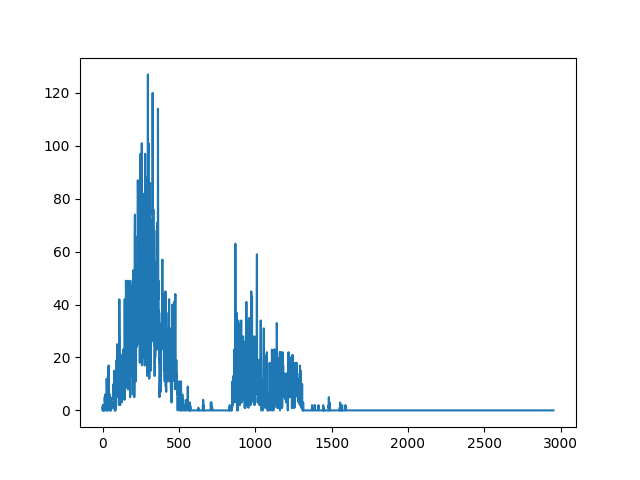

In [85]:
plt.figure()
plt.plot([len(st) for st in block.channel_indexes[12].units[0].spiketrains])
plt.show()

In [84]:
block.channel_indexes[12].units[0]

Unit with 2954 spiketrains
name: 'e10u0'
annotations: {'source': 'data/birds/GreYel3594M/sites/GreYel3594M___170919_094646/manually_curated/curated-e10.pkl'}

In [75]:
block.segments[1000].spiketrains[-11].times.as_array()

array([5500.012     , 5500.40036667, 5500.77026667, 5500.92166667,
       5500.95873333, 5500.97113333, 5501.1473    , 5501.39693333,
       5501.43403333, 5501.46783333, 5501.49386667, 5502.08963333,
       5502.11236667, 5502.31933333])

In [76]:
len(block.segments)

2954

/auto/fhome/kevin/Projects/songephys/env3/lib/python3.5/site-packages/matplotlib/pyplot.py:524: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).
  max_open_warning, RuntimeWarning)


<IPython.core.display.Javascript object>


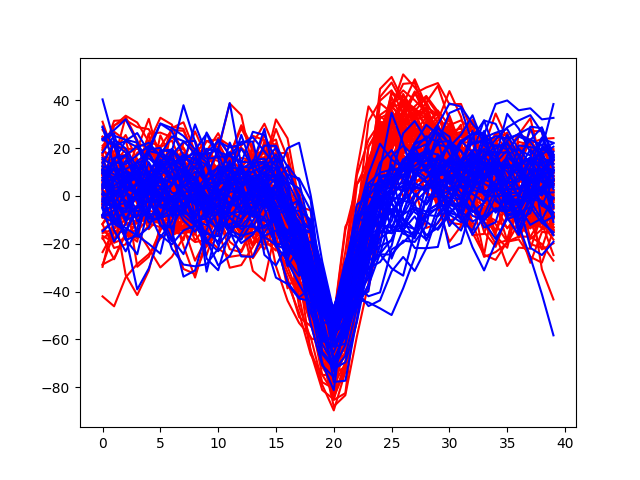

In [77]:
fig = plt.figure()
plt.plot(block.segments[2001].spiketrains[-10].waveforms.T, color="Red")
plt.plot(block.segments[2001].spiketrains[-9].waveforms.T, color="Blue")

plt.show()

/auto/fhome/kevin/Projects/songephys/env3/lib/python3.5/site-packages/matplotlib/pyplot.py:524: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).
  max_open_warning, RuntimeWarning)


<IPython.core.display.Javascript object>


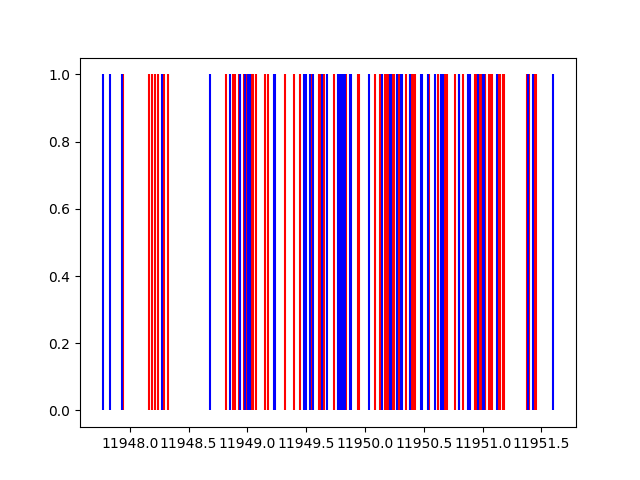

In [78]:
plt.figure()
plt.vlines(block.segments[2001].spiketrains[-10], 0, 1, "r")
plt.vlines(block.segments[2001].spiketrains[-9], 0, 1, "b")
plt.show()